# Multiple Linear Regression

In [1]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
import seaborn as sns
#from sklearn.linear_model import MutlipleLinearRegression


In [2]:
data = pd.read_csv(r"E:\AI_ML_Training\AI_ML\raw_materials\Bengaluru_House_Price.csv")
data.head()

,area_type,availability,location,size,society,total_sqft,bath,balcony,price
0,Super built-up Area,19-Dec,Electronic City Phase II,2 BHK,Coomee,1056,2.0,1.0,39.07
1,Plot Area,Ready To Move,Chikka Tirupathi,4 Bedroom,Theanmp,2600,5.0,3.0,120.00
2,Built-up Area,Ready To Move,Uttarahalli,3 BHK,NaN,1440,2.0,3.0,62.00
3,Super built-up Area,Ready To Move,Lingadheeranahalli,3 BHK,Soiewre,1521,3.0,1.0,95.00
4,Super built-up Area,Ready To Move,Kothanur,2 BHK,NaN,1200,2.0,1.0,51.00


In [3]:
print("Shape of the Dataset :")
data.shape

Shape of the Dataset :


(13320, 9)

In [4]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 13320 entries, 0 to 13319
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   area_type     13320 non-null  object 
 1   availability  13320 non-null  object 
 2   location      13319 non-null  object 
 3   size          13304 non-null  object 
 4   society       7818 non-null   object 
 5   total_sqft    13320 non-null  object 
 6   bath          13247 non-null  float64
 7   balcony       12711 non-null  float64
 8   price         13320 non-null  float64
dtypes: float64(3), object(6)
memory usage: 936.7+ KB


In [5]:
print("Checking null values in data :")
data.isnull().sum()

Checking null values in data :


area_type          0
availability       0
location           1
size              16
society         5502
total_sqft         0
bath              73
balcony          609
price              0
dtype: int64

In [6]:
print("Accessing the last 5 rows :")
data.tail()

Accessing the last 5 rows :


,area_type,availability,location,size,society,total_sqft,bath,balcony,price
13315,Built-up Area,Ready To Move,Whitefield,5 Bedroom,ArsiaEx,3453,4.0,0.0,231.0
13316,Super built-up Area,Ready To Move,Richards Town,4 BHK,NaN,3600,5.0,NaN,400.0
13317,Built-up Area,Ready To Move,Raja Rajeshwari Nagar,2 BHK,Mahla T,1141,2.0,1.0,60.0
13318,Super built-up Area,18-Jun,Padmanabhanagar,4 BHK,SollyCl,4689,4.0,1.0,488.0
13319,Super built-up Area,Ready To Move,Doddathoguru,1 BHK,NaN,550,1.0,1.0,17.0


In [7]:
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", None)

In [8]:
data.head()

,area_type,availability,location,size,society,total_sqft,bath,balcony,price
0,Super built-up Area,19-Dec,Electronic City Phase II,2 BHK,Coomee,1056,2.0,1.0,39.07
1,Plot Area,Ready To Move,Chikka Tirupathi,4 Bedroom,Theanmp,2600,5.0,3.0,120.00
2,Built-up Area,Ready To Move,Uttarahalli,3 BHK,NaN,1440,2.0,3.0,62.00
3,Super built-up Area,Ready To Move,Lingadheeranahalli,3 BHK,Soiewre,1521,3.0,1.0,95.00
4,Super built-up Area,Ready To Move,Kothanur,2 BHK,NaN,1200,2.0,1.0,51.00


In [9]:
print("Display all statistical data of Dataset :")
data.describe()

Display all statistical data of Dataset :


,bath,balcony,price
count,13247.000000,12711.000000,13320.000000
mean,2.692610,1.584376,112.565627
std,1.341458,0.817263,148.971674
min,1.000000,0.000000,8.000000
25%,2.000000,1.000000,50.000000
50%,2.000000,2.000000,72.000000
75%,3.000000,2.000000,120.000000
max,40.000000,3.000000,3600.000000


<Figure size 1500x700 with 0 Axes>

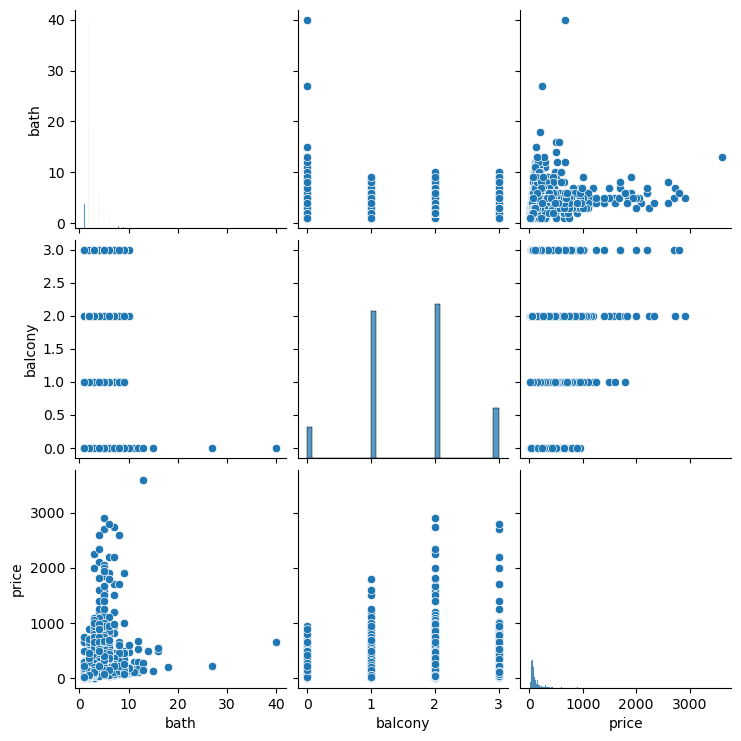

In [10]:
plt.figure(figsize= (15,7))
sns.pairplot(data)

In [11]:
print("ALL Columns of Dataset")
data.columns

ALL Columns of Dataset


Index(['area_type', 'availability', 'location', 'size', 'society',
       'total_sqft', 'bath', 'balcony', 'price'],
      dtype='object')

In [12]:
# Defining a function to count the values for each columns
def value_count(data):
    for col in data.columns:
        print(data[col].value_counts())
        print("--"*8)


value_count(data)

area_type
Super built-up  Area    8790
Built-up  Area          2418
Plot  Area              2025
Carpet  Area              87
Name: count, dtype: int64
----------------
availability
Ready To Move           10581
18-Dec                    307
18-May                    295
18-Apr                    271
18-Aug                    200
19-Dec                    185
18-Jul                    143
18-Mar                    131
18-Jun                     99
20-Dec                     98
21-Dec                     93
19-Mar                     88
18-Feb                     62
18-Nov                     47
18-Jan                     43
18-Sep                     41
19-Jun                     40
18-Oct                     39
19-Jan                     39
19-Jul                     36
17-Dec                     29
20-Jan                     24
19-Sep                     21
17-Oct                     21
22-Jun                     19
19-Aug                     18
21-Jun                     17
Immediat

## Feature Construction

<Axes: >

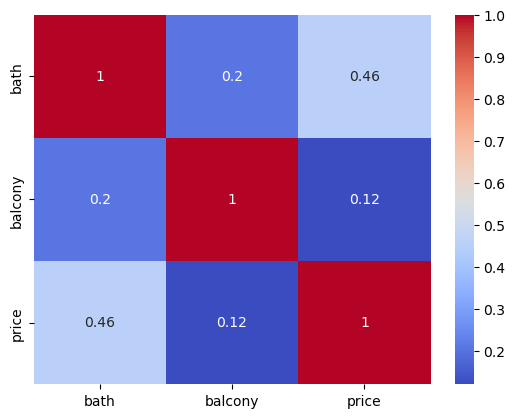

In [13]:
num_col = ['bath', 'balcony', 'price']
sns.heatmap(data[num_col].corr(), cmap = 'coolwarm', annot = True)

## Here we can conclude that the corelation between "bath vs price" is 46% compare to "price vs balcony" 12% so clean of bath column is important.

In [14]:
data.isnull().sum()

area_type          0
availability       0
location           1
size              16
society         5502
total_sqft         0
bath              73
balcony          609
price              0
dtype: int64

In [15]:
data.isnull().mean()*100

area_type        0.000000
availability     0.000000
location         0.007508
size             0.120120
society         41.306306
total_sqft       0.000000
bath             0.548048
balcony          4.572072
price            0.000000
dtype: float64

<Axes: >

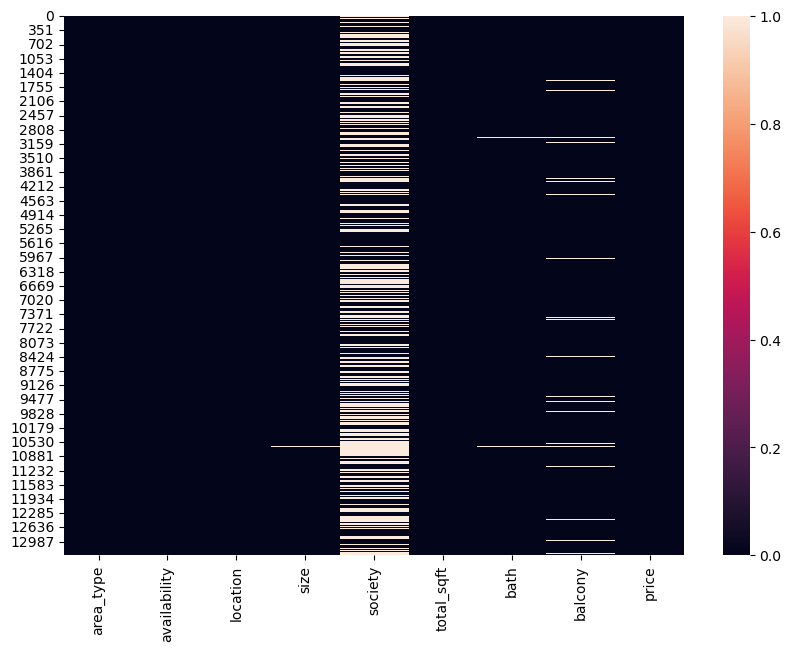

In [16]:
plt.figure(figsize = (10,7))
sns.heatmap(data.isnull())

In [17]:
data_2 = data.drop('society', axis = 'columns')
data_2.shape

(13320, 8)

In [18]:
data_2['balcony'] = data_2['balcony'].fillna(data_2['balcony'].mean())
data_2.isnull().sum()

area_type        0
availability     0
location         1
size            16
total_sqft       0
bath            73
balcony          0
price            0
dtype: int64

In [19]:
data_2 = data_2.dropna()
data_2.isnull().sum()

area_type       0
availability    0
location        0
size            0
total_sqft      0
bath            0
balcony         0
price           0
dtype: int64

In [20]:
data_2.shape

(13246, 8)

## Feature Engineering 

In [21]:
data_2['total_sqft'].value_counts()

total_sqft
1200                 843
1100                 221
1500                 204
2400                 195
600                  180
1000                 172
1350                 132
1050                 123
1300                 117
1250                 114
900                  112
1400                 108
1800                 104
1150                 101
1600                 100
1140                  91
2000                  82
1450                  70
1650                  69
800                   67
1075                  66
3000                  66
1020                  63
2500                  62
1125                  60
1160                  60
1550                  60
950                   59
1180                  58
1700                  58
1260                  57
1255                  56
1080                  55
1220                  55
1070                  53
750                   52
700                   52
1225                  48
4000                  48
1175          

In [22]:
total_sqft_int = []
for str_val in data_2['total_sqft']:
    try:
        total_sqft_int.append(float(str_val))
    except:
        try:
            temp = []
            temp = str_val.split(' - ')
            total_sqft_int.append(float(float(temp[0])+float(temp[-1]))/2)
        
        except:
            total_sqft_int.append(np.nan)

In [23]:
data_4 = data_2.reset_index(drop = True)

In [24]:
data_5 = data_4.join(pd.DataFrame({'total_sqft_int' : total_sqft_int}))
data_5.head()

,area_type,availability,location,size,total_sqft,bath,balcony,price,total_sqft_int
0,Super built-up Area,19-Dec,Electronic City Phase II,2 BHK,1056,2.0,1.0,39.07,1056.0
1,Plot Area,Ready To Move,Chikka Tirupathi,4 Bedroom,2600,5.0,3.0,120.00,2600.0
2,Built-up Area,Ready To Move,Uttarahalli,3 BHK,1440,2.0,3.0,62.00,1440.0
3,Super built-up Area,Ready To Move,Lingadheeranahalli,3 BHK,1521,3.0,1.0,95.00,1521.0
4,Super built-up Area,Ready To Move,Kothanur,2 BHK,1200,2.0,1.0,51.00,1200.0


In [25]:
data_5.isnull().sum()

area_type          0
availability       0
location           0
size               0
total_sqft         0
bath               0
balcony            0
price              0
total_sqft_int    46
dtype: int64

In [26]:
data_6 = data_5.dropna()
data_6.shape

(13200, 9)

In [27]:
data_6.info()

<class 'pandas.core.frame.DataFrame'>
Index: 13200 entries, 0 to 13245
Data columns (total 9 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   area_type       13200 non-null  object 
 1   availability    13200 non-null  object 
 2   location        13200 non-null  object 
 3   size            13200 non-null  object 
 4   total_sqft      13200 non-null  object 
 5   bath            13200 non-null  float64
 6   balcony         13200 non-null  float64
 7   price           13200 non-null  float64
 8   total_sqft_int  13200 non-null  float64
dtypes: float64(4), object(5)
memory usage: 1.0+ MB


In [28]:
data_6['size'].value_counts()

size
2 BHK         5192
3 BHK         4277
4 Bedroom      816
4 BHK          574
3 Bedroom      541
1 BHK          527
2 Bedroom      325
5 Bedroom      293
6 Bedroom      190
1 Bedroom      100
8 Bedroom       83
7 Bedroom       83
5 BHK           56
9 Bedroom       45
6 BHK           30
7 BHK           17
1 RK            13
10 Bedroom      12
9 BHK            7
8 BHK            5
11 BHK           2
10 BHK           2
11 Bedroom       2
27 BHK           1
19 BHK           1
43 Bedroom       1
16 BHK           1
14 BHK           1
12 Bedroom       1
13 BHK           1
18 Bedroom       1
Name: count, dtype: int64

In [29]:
size_int = []
for str_val in data_6['size']:
    try:
        val = str_val.split(" ")
        size_int.append(float(val[0]))
    except:
        size_int.append(np.nan)
        

In [30]:
data_7 = data_6.join(pd.DataFrame({'BHK' : size_int}))
data_7.head()

,area_type,availability,location,size,total_sqft,bath,balcony,price,total_sqft_int,BHK
0,Super built-up Area,19-Dec,Electronic City Phase II,2 BHK,1056,2.0,1.0,39.07,1056.0,2.0
1,Plot Area,Ready To Move,Chikka Tirupathi,4 Bedroom,2600,5.0,3.0,120.00,2600.0,4.0
2,Built-up Area,Ready To Move,Uttarahalli,3 BHK,1440,2.0,3.0,62.00,1440.0,3.0
3,Super built-up Area,Ready To Move,Lingadheeranahalli,3 BHK,1521,3.0,1.0,95.00,1521.0,3.0
4,Super built-up Area,Ready To Move,Kothanur,2 BHK,1200,2.0,1.0,51.00,1200.0,2.0


In [31]:
data_7.isnull().sum()

area_type          0
availability       0
location           0
size               0
total_sqft         0
bath               0
balcony            0
price              0
total_sqft_int     0
BHK               46
dtype: int64

In [32]:
data_8 = data_7.dropna()
data_8.shape

(13154, 10)

# Scaling the Features

## Using Standard Scaling

In [33]:
from sklearn.preprocessing import StandardScaler

In [34]:
train_data = data_8[['total_sqft_int', 'BHK', 'bath', 'balcony', 'price']]
train_data.head()

,total_sqft_int,BHK,bath,balcony,price
0,1056.0,2.0,2.0,1.0,39.07
1,2600.0,4.0,5.0,3.0,120.00
2,1440.0,3.0,2.0,3.0,62.00
3,1521.0,3.0,3.0,1.0,95.00
4,1200.0,2.0,2.0,1.0,51.00


In [35]:
x = train_data.drop('price', axis = 1)
y = train_data['price']
print(f"Shape of x : {x.shape}")
print(f"Shape of y : {y.shape}")

Shape of x : (13154, 4)
Shape of y : (13154,)


In [36]:
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size= 0.2, random_state= 42)
print(f"Shape of x_train : {x_train.shape}")
print(f"Shape of x_test : {x_test.shape}")
print(f"Shape of y_train : {y_train.shape}")
print(f"Shape of y_test : {y_test.shape}")

Shape of x_train : (10523, 4)
Shape of x_test : (2631, 4)
Shape of y_train : (10523,)
Shape of y_test : (2631,)


In [37]:
std_scaler = StandardScaler()

In [38]:
x_train_scaled = std_scaler.fit_transform(x_train)
x_test_scaled = std_scaler.fit_transform(x_test)

print("Tranformed Values of X_Train",x_train_scaled)
print("Tranformed Values of X_Test",x_test_scaled)

Tranformed Values of X_Train [[-0.30961905 -0.64093857 -0.53599459 -0.72206317]
 [-0.54650861 -1.4496432   0.24175928 -1.96616436]
 [-0.36131807  0.16776606 -0.53599459  0.52203803]
 ...
 [-0.21856703 -0.64093857 -0.53599459  0.52203803]
 [-0.32273671  0.16776606 -0.53599459 -0.72206317]
 [ 0.00443324  0.97647069  0.24175928 -0.72206317]]
Tranformed Values of X_Test [[-0.54652226 -0.55590141 -0.45326839  0.50215685]
 [-0.38133504  0.11102819 -0.45326839  0.50215685]
 [-0.38749108 -0.55590141 -0.45326839  0.50215685]
 ...
 [-0.34132074  0.11102819 -0.45326839 -0.77129914]
 [-0.58243253 -0.55590141 -0.45326839 -0.77129914]
 [-0.3351647   0.77795779 -0.45326839 -0.77129914]]


In [39]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score, root_mean_squared_error

In [40]:
model_1 = LinearRegression()

In [41]:
model_1.fit(x_train_scaled, y_train)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [42]:
y_pred = model_1.predict(x_test_scaled)

print(f" r2 Score of Test dataset is : {r2_score(y_test, y_pred)}")

 r2 Score of Test dataset is : 0.45918475079295284


In [43]:
print(f" r2 Score is : {r2_score(y_test, y_pred)}")
print(f" mean absolute error is : {mean_absolute_error(y_test, y_pred)}")
print(f" mean sqaured error is : {mean_squared_error(y_test, y_pred)}")
print(f" root mean squared error : {root_mean_squared_error(y_test, y_pred)}")

 r2 Score is : 0.45918475079295284
 mean absolute error is : 44.4175200220458
 mean sqaured error is : 12261.674322710767
 root mean squared error : 110.73244476083225


In [44]:
# Predicting on user given features
# train_data = data_8[['total_sqft_int', 'BHK', 'bath', 'balcony', 'price']]
user = [[1500, 2, 2, 1]]

print(f" Predicted price for user given data : {model_1.predict(user)}")

 Predicted price for user given data : [100302.13722768]


## Removing Outlier using IQR method

In [45]:
def remove_outlier_IQR(data_2, column):
    Q1 = data_2[column].quantile(0.25)

    Q3 = data_2[column].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5*IQR
    upper_bound = Q3 + 1.5*IQR

    print(f"{column} outlier boundaries :")
    print("Q1 : ", Q1)
    print("Q2 : ", Q3)
    print("IQR : ", IQR)
    print("lower_bound :", lower_bound)
    print("Upper_bound :", upper_bound)

    filtered_data = data_2[(data_2[column] >= lower_bound) & (data_2[column] <= upper_bound)]

    return filtered_data

In [46]:
train_data_clean = remove_outlier_IQR(train_data, 'total_sqft_int')

print("After total_sqft_int outlier removal")
train_data_clean.shape

total_sqft_int outlier boundaries :
Q1 :  1100.0
Q2 :  1671.5
IQR :  571.5
lower_bound : 242.75
Upper_bound : 2528.75
After total_sqft_int outlier removal


(12010, 5)

In [47]:
train_data_clean = remove_outlier_IQR(train_data, 'BHK')

print("After BHK outlier removal")
train_data_clean.shape

BHK outlier boundaries :
Q1 :  2.0
Q2 :  3.0
IQR :  1.0
lower_bound : 0.5
Upper_bound : 4.5
After BHK outlier removal


(12321, 5)

In [48]:
train_data_clean = remove_outlier_IQR(train_data, 'bath')

print("After bath outlier removal")
train_data_clean.shape

bath outlier boundaries :
Q1 :  2.0
Q2 :  3.0
IQR :  1.0
lower_bound : 0.5
Upper_bound : 4.5
After bath outlier removal


(12134, 5)

In [49]:
train_data_clean = remove_outlier_IQR(train_data, 'balcony')

print("After balcony outlier removal")
train_data_clean.shape

balcony outlier boundaries :
Q1 :  1.0
Q2 :  2.0
IQR :  1.0
lower_bound : -0.5
Upper_bound : 3.5
After balcony outlier removal


(13154, 5)

In [50]:
train_data_clean = remove_outlier_IQR(train_data, 'price')

print("After price outlier removal")
train_data_clean.shape

price outlier boundaries :
Q1 :  50.0
Q2 :  120.0
IQR :  70.0
lower_bound : -55.0
Upper_bound : 225.0
After price outlier removal


(11910, 5)

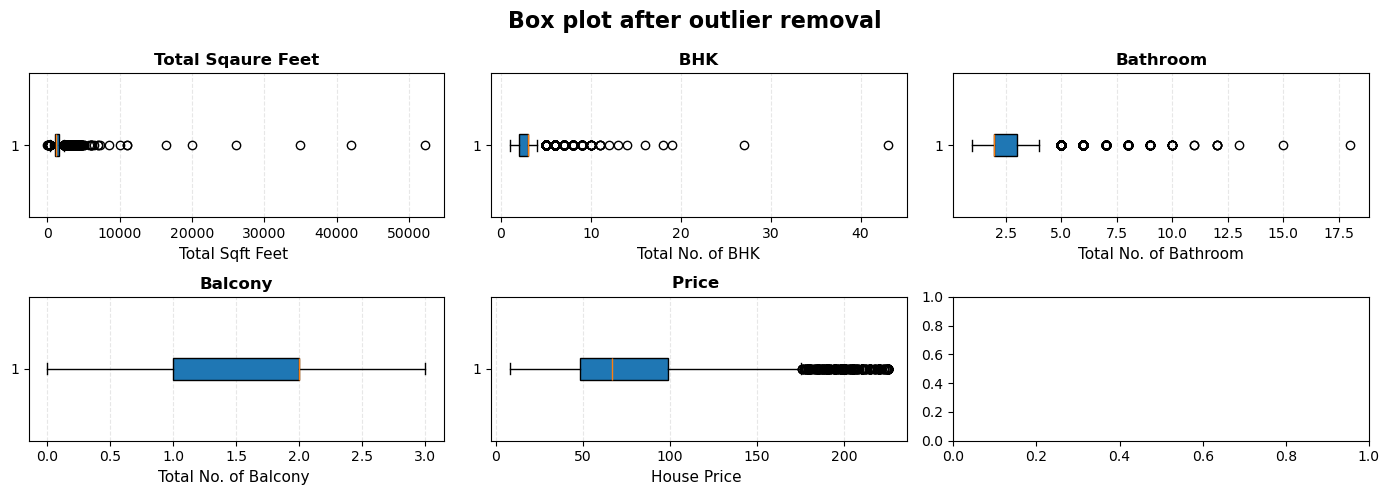

In [51]:
fig, axes = plt.subplots(2,3, figsize = (14, 5))

axes[0][0].boxplot(train_data_clean['total_sqft_int'], vert = False, patch_artist = True)
axes[0][0].set_title("Total Sqaure Feet", fontsize = 12, fontweight = "bold")
axes[0][0].set_xlabel("Total Sqft Feet ", fontsize = 11)
axes[0][0].grid(axis = 'x', linestyle = "--", alpha = 0.3)

axes[0][1].boxplot(train_data_clean['BHK'], vert = False, patch_artist = True)
axes[0][1].set_title(" BHK ", fontsize = 12, fontweight = "bold")
axes[0][1].set_xlabel("Total No. of BHK", fontsize = 11)
axes[0][1].grid(axis = 'x', linestyle = "--", alpha = 0.3)

axes[0][2].boxplot(train_data_clean['bath'], vert = False, patch_artist = True)
axes[0][2].set_title("Bathroom", fontsize = 12, fontweight = "bold")
axes[0][2].set_xlabel("Total No. of Bathroom", fontsize = 11)
axes[0][2].grid(axis = 'x', linestyle = "--", alpha = 0.3)

axes[1][0].boxplot(train_data_clean['balcony'], vert = False, patch_artist = True)
axes[1][0].set_title("Balcony", fontsize = 12, fontweight = "bold")
axes[1][0].set_xlabel("Total No. of Balcony ", fontsize = 11)
axes[1][0].grid(axis = 'x', linestyle = "--", alpha = 0.3)

axes[1][1].boxplot(train_data_clean['price'], vert = False, patch_artist = True)
axes[1][1].set_title("Price ", fontsize = 12, fontweight = "bold")
axes[1][1].set_xlabel("House Price ", fontsize = 11)
axes[1][1].grid(axis = 'x', linestyle = "--", alpha = 0.3)

plt.suptitle("Box plot after outlier removal", fontsize = 16, fontweight = "bold")
plt.tight_layout()

In [52]:
train_data_clean.isnull().sum()

total_sqft_int    0
BHK               0
bath              0
balcony           0
price             0
dtype: int64

In [53]:
x_2 = train_data_clean.drop('price', axis = 1)
y_2 = train_data_clean['price']

print(f"Shape of x_2 : {x_2.shape}")
print(f"Shape of y_2 : {y_2.shape}")

Shape of x_2 : (11910, 4)
Shape of y_2 : (11910,)


In [54]:
x_train_2, x_test_2, y_train_2, y_test_2 = train_test_split(x_2, y_2, test_size= 0.2, random_state= 42)
print(f"Shape of x_train_2 : {x_train_2.shape}")
print(f"Shape of x_test_2 : {x_test_2.shape}")
print(f"Shape of y_train_2 : {y_train_2.shape}")
print(f"Shape of y_test_2 : {y_test_2.shape}")

Shape of x_train_2 : (9528, 4)
Shape of x_test_2 : (2382, 4)
Shape of y_train_2 : (9528,)
Shape of y_test_2 : (2382,)


In [55]:
x_train_scaled_2 = std_scaler.fit_transform(x_train_2)
print("x_train_2  values after Standard transformation : ", x_train_scaled_2)

x_train_2  values after Standard transformation :  [[ 1.13167928 -0.60770335  1.34057558  0.54690841]
 [-0.34724761  0.90646965 -0.45958003  0.54690841]
 [-0.42833164  1.66355615 -0.45958003  0.54690841]
 ...
 [-0.3586679  -0.60770335 -0.45958003  1.80569398]
 [-0.88400101  0.14938315  1.34057558 -1.97066275]
 [-0.19878391  0.90646965 -0.45958003  1.80569398]]


In [56]:
x_test_scaled_2 = std_scaler.fit_transform(x_test_2)
print("x_test_2  values after Standard transformation : ", x_test_scaled_2)

x_test_2  values after Standard transformation :  [[ 0.1035395  -0.65776444 -0.4604342  -0.71786206]
 [-0.165209   -0.65776444  5.82211887  1.86595718]
 [ 0.11518527 -0.65776444  0.43707338 -0.71786206]
 ...
 [-0.02859518  0.15194868 -0.4604342  -2.00977167]
 [-0.24135442 -0.65776444 -0.4604342   0.57404756]
 [-0.25479184  0.15194868 -0.4604342  -0.71786206]]


In [57]:
model_2 = LinearRegression()


In [58]:
model_2.fit(x_train_scaled_2, y_train_2)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [59]:
y_pred_2 = model_2.predict(x_test_scaled_2)

In [60]:
print(f" r2 Score is : {r2_score(y_test_2, y_pred_2)}")
print(f" mean absolute error is : {mean_absolute_error(y_test_2, y_pred_2)}")
print(f" mean sqaured error is : {mean_squared_error(y_test_2, y_pred_2)}")
print(f" root mean squared error : {root_mean_squared_error(y_test_2, y_pred_2)}")

 r2 Score is : 0.38008191545230474
 mean absolute error is : 24.55023155877583
 mean sqaured error is : 1178.6308019036337
 root mean squared error : 34.331192841257845
